In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer

In [126]:
df = pd.read_csv("Apartments Prices Dataset.csv")

In [127]:
df.shape

(5578, 11)

In [128]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5578 non-null   object
 1   area_sqm        5578 non-null   object
 2   rooms           5578 non-null   object
 3   bathrooms       5578 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5578 non-null   object
 7   view            5578 non-null   object
 8   price_per_sqm   5578 non-null   object
 9   payment_method  5578 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [129]:
df.duplicated().sum()

1489

In [130]:
df.drop_duplicates(inplace =True)

In [131]:
df.isnull().sum()

price             0
area_sqm          0
rooms             0
bathrooms         0
floor_level       0
year_built        0
seller_type       0
view              0
price_per_sqm     0
payment_method    0
finishing_type    0
dtype: int64

In [132]:
df.describe()

,year_built
count,4089.000000
mean,2021.928833
std,8.870374
min,1915.000000
25%,2022.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [133]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [134]:
df_clean = clean_real_estate_data(df)

In [135]:
df_clean

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000,120,2,NaN,3,2025,Developer,Main Street,18025.0,Installments,Semi Finished
1,3250000,162,3,NaN,6,2024,Developer,Main Street,20062.0,Cash Or Installments,Semi Finished
2,2650000,122,3,NaN,4,2024,Developer,Main Street,21721.0,Cash Or Installments,Semi Finished
3,12720000,212,4,NaN,13,2027,Broker,Club,60000.0,Cash Or Installments,Extra Super Lux
4,5898000,135,2,NaN,6,2025,Developer,Lake,43689.0,Cash Or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
5571,5050000,101,2,NaN,2,2027,Broker,Pool,50000.0,Installments,Super Lux
5574,2800000,180,3,NaN,3,2019,Broker,Side Street,15556.0,Cash,Extra Super Lux
5575,6000000,215,3,NaN,7,2025,Broker,Other,27907.0,Cash,Semi Finished
5576,7500000,400,4,NaN,11,2009,Broker,Main Street,18750.0,Cash,Super Lux


In [136]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4089 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           4089 non-null   object
 1   area_sqm        4089 non-null   object
 2   rooms           4089 non-null   object
 3   bathrooms       4089 non-null   object
 4   floor_level     4089 non-null   object
 5   year_built      4089 non-null   int64 
 6   seller_type     4089 non-null   object
 7   view            4089 non-null   object
 8   price_per_sqm   4089 non-null   object
 9   payment_method  4089 non-null   object
 10  finishing_type  4089 non-null   object
dtypes: int64(1), object(10)
memory usage: 383.3+ KB


In [137]:
df

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
5571,"5,050,000 EGP",101 m²,2 rooms,1 bathroom,2,2027,Broker,Pool,"50,000 EGP/M²",Installments,Super Lux
5574,"2,800,000 EGP",180 m²,3 rooms,2 bathroom,3,2019,Broker,Side Street,"15,556 EGP/M²",Cash,Extra Super Lux
5575,"6,000,000 EGP",215 m²,3 rooms,2 bathroom,7,2025,Broker,Other,"27,907 EGP/M²",Cash,Semi Finished
5576,"7,500,000 EGP",400 m²,4 rooms,3 bathroom,11,2009,Broker,Main Street,"18,750 EGP/M²",Cash,Super Lux


In [138]:
cols_to_split = ['price','price_per_sqm','bathrooms','rooms','area_sqm']

In [139]:
for col in cols_to_split:
    df[col] = df[col].apply(lambda x : x.split()[0])

In [140]:
df

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000",120,2,3,3,2025,Developer,Main Street,"18,025",Installments,Semi Finished
1,"3,250,000",162,3,2,6,2024,Developer,Main Street,"20,062",Cash or Installments,Semi Finished
2,"2,650,000",122,3,1,4,2024,Developer,Main Street,"21,721",Cash or Installments,Semi Finished
3,"12,720,000",212,4,3,13,2027,Broker,Club,"60,000",Cash or Installments,Extra Super Lux
4,"5,898,000",135,2,1,6,2025,Developer,Lake,"43,689",Cash or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
5571,"5,050,000",101,2,1,2,2027,Broker,Pool,"50,000",Installments,Super Lux
5574,"2,800,000",180,3,2,3,2019,Broker,Side Street,"15,556",Cash,Extra Super Lux
5575,"6,000,000",215,3,2,7,2025,Broker,Other,"27,907",Cash,Semi Finished
5576,"7,500,000",400,4,3,11,2009,Broker,Main Street,"18,750",Cash,Super Lux


In [141]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4089 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           4089 non-null   object
 1   area_sqm        4089 non-null   object
 2   rooms           4089 non-null   object
 3   bathrooms       4089 non-null   object
 4   floor_level     4089 non-null   object
 5   year_built      4089 non-null   int64 
 6   seller_type     4089 non-null   object
 7   view            4089 non-null   object
 8   price_per_sqm   4089 non-null   object
 9   payment_method  4089 non-null   object
 10  finishing_type  4089 non-null   object
dtypes: int64(1), object(10)
memory usage: 383.3+ KB


In [142]:
df['price_per_sqm'] = df['price_per_sqm'].str.replace(',',"").str.strip()
df['price'] = df['price'].str.replace(',',"").str.strip()

In [143]:
df

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000,120,2,3,3,2025,Developer,Main Street,18025,Installments,Semi Finished
1,3250000,162,3,2,6,2024,Developer,Main Street,20062,Cash or Installments,Semi Finished
2,2650000,122,3,1,4,2024,Developer,Main Street,21721,Cash or Installments,Semi Finished
3,12720000,212,4,3,13,2027,Broker,Club,60000,Cash or Installments,Extra Super Lux
4,5898000,135,2,1,6,2025,Developer,Lake,43689,Cash or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
5571,5050000,101,2,1,2,2027,Broker,Pool,50000,Installments,Super Lux
5574,2800000,180,3,2,3,2019,Broker,Side Street,15556,Cash,Extra Super Lux
5575,6000000,215,3,2,7,2025,Broker,Other,27907,Cash,Semi Finished
5576,7500000,400,4,3,11,2009,Broker,Main Street,18750,Cash,Super Lux


In [144]:
for col in cols_to_split:
  # Coerce invalid parsing to NaN, then convert to pandas nullable Int64
  df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

In [145]:
df.isnull().sum()

price              0
area_sqm           0
rooms              0
bathrooms          0
floor_level        0
year_built         0
seller_type        0
view               0
price_per_sqm     30
payment_method     0
finishing_type     0
dtype: int64

In [146]:
df = df.dropna()

In [147]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4059 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           4059 non-null   Int64 
 1   area_sqm        4059 non-null   Int64 
 2   rooms           4059 non-null   Int64 
 3   bathrooms       4059 non-null   Int64 
 4   floor_level     4059 non-null   object
 5   year_built      4059 non-null   int64 
 6   seller_type     4059 non-null   object
 7   view            4059 non-null   object
 8   price_per_sqm   4059 non-null   Int64 
 9   payment_method  4059 non-null   object
 10  finishing_type  4059 non-null   object
dtypes: Int64(5), int64(1), object(5)
memory usage: 400.4+ KB


In [148]:
df.select_dtypes("O")

,floor_level,seller_type,view,payment_method,finishing_type
0,3,Developer,Main Street,Installments,Semi Finished
1,6,Developer,Main Street,Cash or Installments,Semi Finished
2,4,Developer,Main Street,Cash or Installments,Semi Finished
3,13,Broker,Club,Cash or Installments,Extra Super Lux
4,6,Developer,Lake,Cash or Installments,Super Lux
...,...,...,...,...,...
5571,2,Broker,Pool,Installments,Super Lux
5574,3,Broker,Side Street,Cash,Extra Super Lux
5575,7,Broker,Other,Cash,Semi Finished
5576,11,Broker,Main Street,Cash,Super Lux


In [149]:
df['floor_level'].unique()

array(['3', '6', '4', '13', '9', '2', 'Ground', '7', '1', '12', '10', '8',
       '5', '22', '64', '11', '18', '16', '15', '17', '14', '32'],
      dtype=object)

In [150]:
df['floor_level']= df['floor_level'].str.replace('Ground','0')

C:\Users\yawaa\AppData\Local\Temp\ipykernel_10948\284580226.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['floor_level']= df['floor_level'].str.replace('Ground','0')


In [151]:
df['floor_level'].unique()

array(['3', '6', '4', '13', '9', '2', '0', '7', '1', '12', '10', '8', '5',
       '22', '64', '11', '18', '16', '15', '17', '14', '32'], dtype=object)

In [152]:
df['floor_level'] = pd.to_numeric(df['floor_level']).astype(np.int64)

C:\Users\yawaa\AppData\Local\Temp\ipykernel_10948\2141115595.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['floor_level'] = pd.to_numeric(df['floor_level']).astype(np.int64)


In [153]:
df.select_dtypes("O")

,seller_type,view,payment_method,finishing_type
0,Developer,Main Street,Installments,Semi Finished
1,Developer,Main Street,Cash or Installments,Semi Finished
2,Developer,Main Street,Cash or Installments,Semi Finished
3,Broker,Club,Cash or Installments,Extra Super Lux
4,Developer,Lake,Cash or Installments,Super Lux
...,...,...,...,...
5571,Broker,Pool,Installments,Super Lux
5574,Broker,Side Street,Cash,Extra Super Lux
5575,Broker,Other,Cash,Semi Finished
5576,Broker,Main Street,Cash,Super Lux


In [154]:
df

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000,120,2,3,3,2025,Developer,Main Street,18025,Installments,Semi Finished
1,3250000,162,3,2,6,2024,Developer,Main Street,20062,Cash or Installments,Semi Finished
2,2650000,122,3,1,4,2024,Developer,Main Street,21721,Cash or Installments,Semi Finished
3,12720000,212,4,3,13,2027,Broker,Club,60000,Cash or Installments,Extra Super Lux
4,5898000,135,2,1,6,2025,Developer,Lake,43689,Cash or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
5571,5050000,101,2,1,2,2027,Broker,Pool,50000,Installments,Super Lux
5574,2800000,180,3,2,3,2019,Broker,Side Street,15556,Cash,Extra Super Lux
5575,6000000,215,3,2,7,2025,Broker,Other,27907,Cash,Semi Finished
5576,7500000,400,4,3,11,2009,Broker,Main Street,18750,Cash,Super Lux


In [155]:

# Define features (X) and target (y)
# Dropping 'price' (target) and 'price_per_sqm' (to avoid data leakage)
X = df.drop(columns=["price", "price_per_sqm"])
y = df["price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4059, 9)
Target shape: (4059,)


In [156]:
import pandas as pd

# Identify categorical columns automatically or explicitly
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()
print("Categorical columns to encode:", categorical_cols)

# Apply One-Hot Encoding
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("Encoded features shape:", X_encoded.shape)
X_encoded.head()

Categorical columns to encode: ['seller_type', 'view', 'payment_method', 'finishing_type']
Encoded features shape: (4059, 26)


,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type_Compound Developer,seller_type_Developer,seller_type_Private Owner,view_Club,view_Corner,...,view_Plaza,view_Pool,view_Sea View,view_Side Street,payment_method_Cash or Installments,payment_method_Installments,finishing_type_Lux,finishing_type_Semi Finished,finishing_type_Super Lux,finishing_type_Without Finish
0,120,2,3,3,2025,False,True,False,False,False,...,False,False,False,False,False,True,False,True,False,False
1,162,3,2,6,2024,False,True,False,False,False,...,False,False,False,False,True,False,False,True,False,False
2,122,3,1,4,2024,False,True,False,False,False,...,False,False,False,False,True,False,False,True,False,False
3,212,4,3,13,2027,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,135,2,1,6,2025,False,True,False,False,False,...,False,False,False,False,True,False,False,False,True,False


In [157]:
from sklearn.model_selection import train_test_split

# Split into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (3247, 26)
Testing set shape: (812, 26)


In [158]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns that need scaling (e.g., area_sqm, rooms, floor_level, year_built)
# Any one-hot encoded boolean columns will automatically be ignored or safely scaled,
# but it's best to target the original continuous/discrete numerical columns:
numerical_cols = [
    "area_sqm",
    "rooms",
    "bathrooms",
    "floor_level",
    "year_built",
]

scaler = StandardScaler()

# Fit on training data only, then transform both train and test sets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

# Preview final scaled training features
X_train_scaled.head()

,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type_Compound Developer,seller_type_Developer,seller_type_Private Owner,view_Club,view_Corner,...,view_Plaza,view_Pool,view_Sea View,view_Side Street,payment_method_Cash or Installments,payment_method_Installments,finishing_type_Lux,finishing_type_Semi Finished,finishing_type_Super Lux,finishing_type_Without Finish
2202,1.241849,0.272923,0.890231,0.371452,0.227406,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4723,1.514670,0.056147,6.887289,2.143574,-1.246196,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
536,-1.831940,-0.377405,-1.108788,-0.691820,0.340760,False,False,False,False,False,...,False,False,True,False,False,True,False,False,True,False
4880,0.477949,0.056147,0.890231,0.725877,0.340760,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5063,0.095999,0.056147,-1.108788,-0.691820,0.340760,False,True,False,False,True,...,False,False,False,False,False,True,False,True,False,False


In [159]:
X_train

,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type_Compound Developer,seller_type_Developer,seller_type_Private Owner,view_Club,view_Corner,...,view_Plaza,view_Pool,view_Sea View,view_Side Street,payment_method_Cash or Installments,payment_method_Installments,finishing_type_Lux,finishing_type_Semi Finished,finishing_type_Super Lux,finishing_type_Without Finish
2202,220,4,3,4,2024,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4723,235,3,9,9,2011,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
536,51,1,1,1,2025,False,False,False,False,False,...,False,False,True,False,False,True,False,False,True,False
4880,178,3,3,5,2025,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5063,157,3,1,1,2025,False,True,False,False,True,...,False,False,False,False,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1748,150,3,2,1,2025,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1980,190,3,2,3,2014,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1120,93,2,1,1,2026,False,False,False,False,False,...,False,True,False,False,False,True,False,False,True,False
4904,125,3,2,3,2025,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True


In [160]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [161]:

def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [162]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [163]:
from tqdm import tqdm

  0%|          | 0/15 [00:00<?, ?it/s]

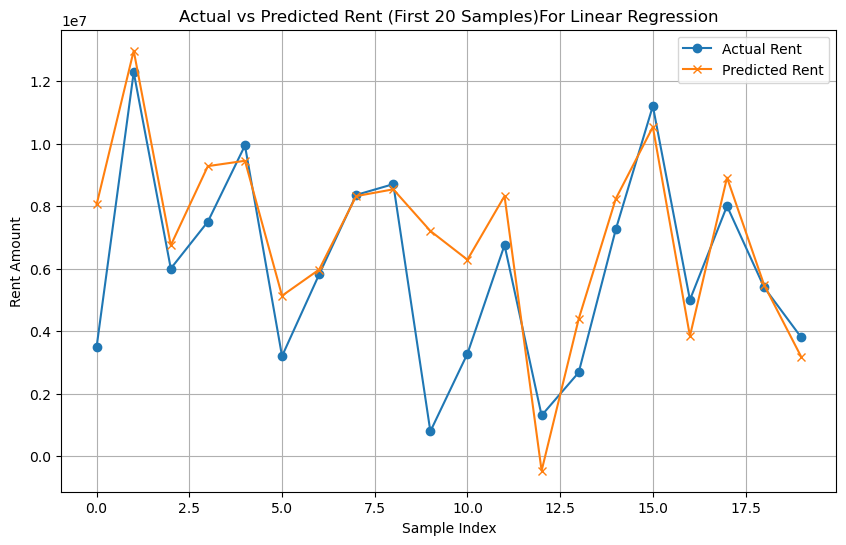

  7%|▋         | 1/15 [00:00<00:06,  2.12it/s]

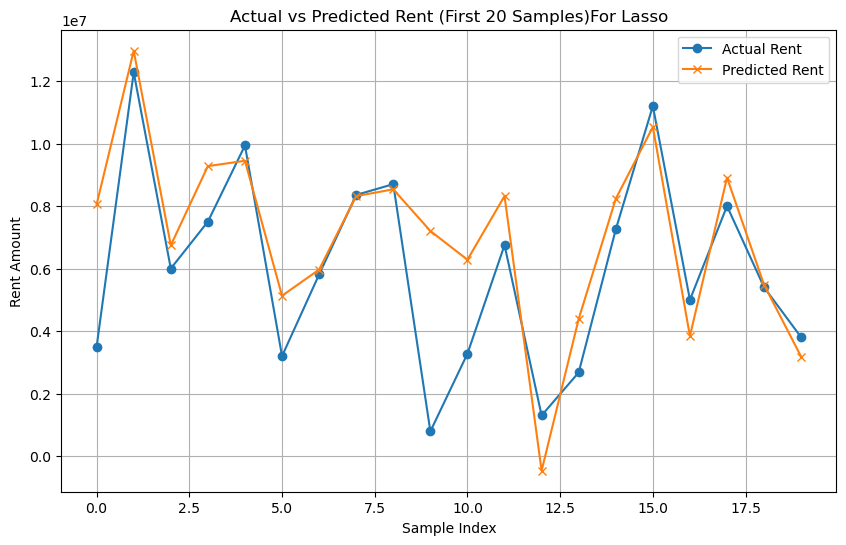

 13%|█▎        | 2/15 [00:00<00:06,  2.10it/s]

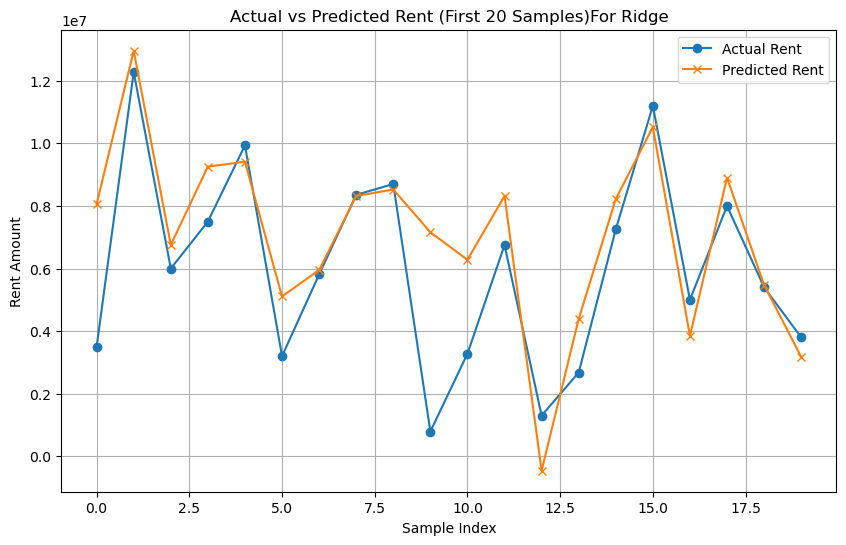

 20%|██        | 3/15 [00:01<00:05,  2.30it/s]

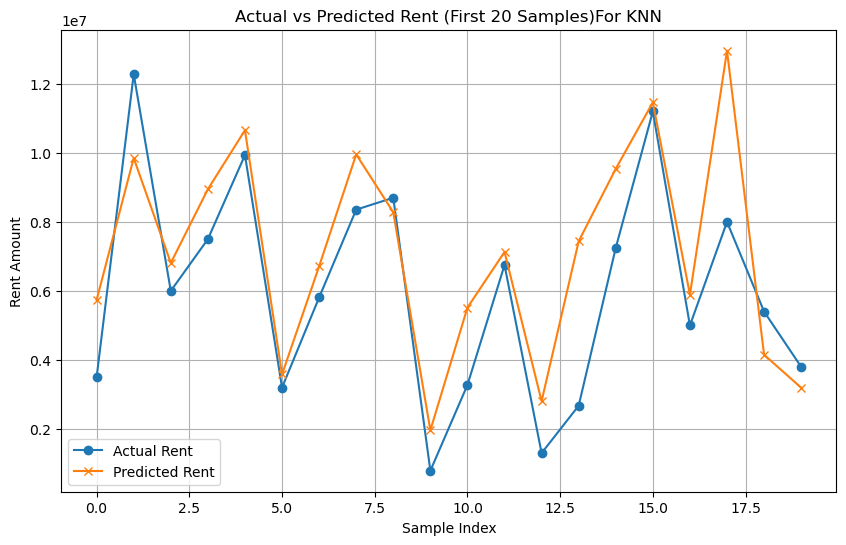

 27%|██▋       | 4/15 [00:02<00:06,  1.62it/s]

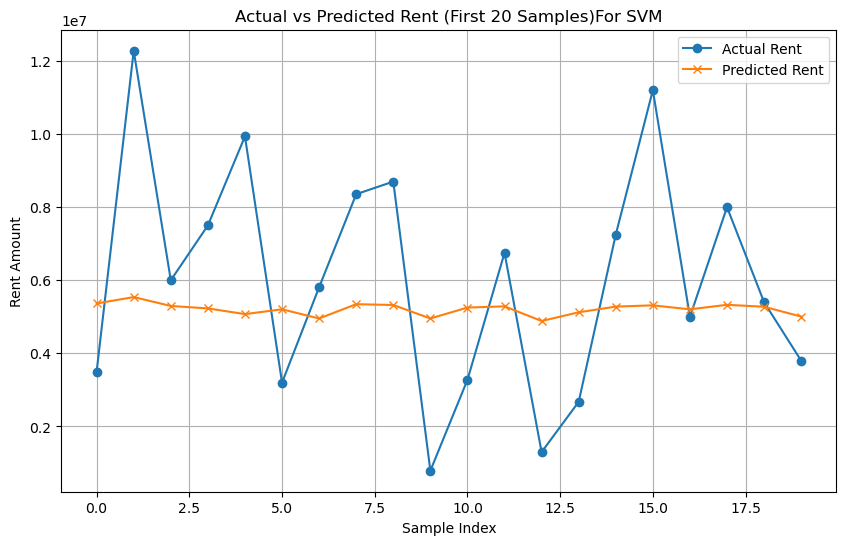

 33%|███▎      | 5/15 [00:03<00:09,  1.05it/s]

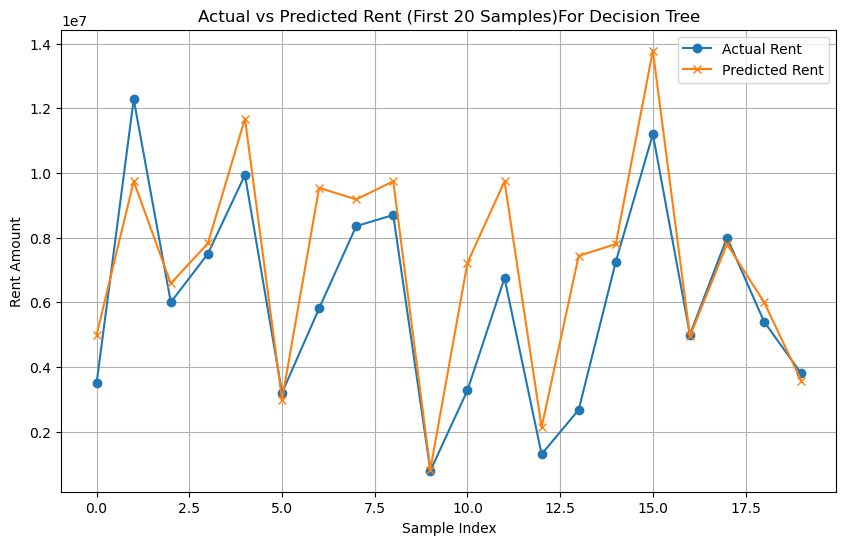

 40%|████      | 6/15 [00:04<00:06,  1.37it/s]

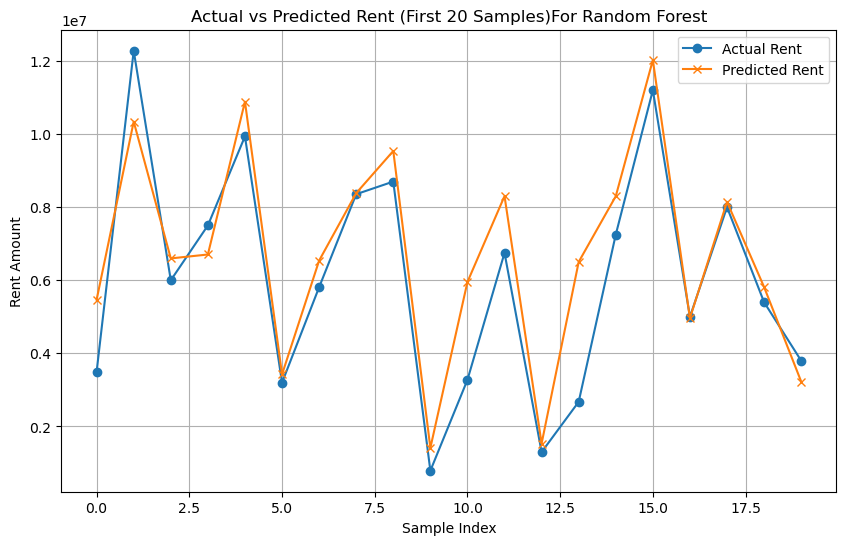

 47%|████▋     | 7/15 [00:04<00:06,  1.32it/s]

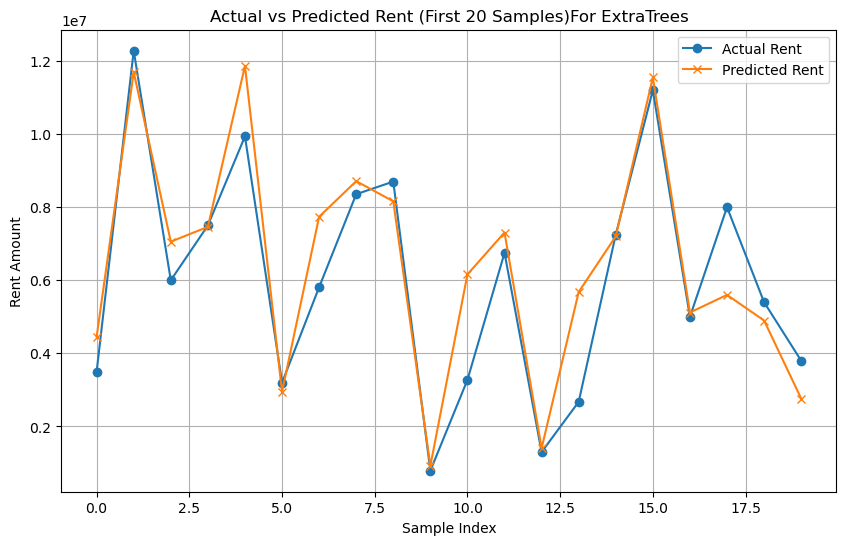

 53%|█████▎    | 8/15 [00:06<00:08,  1.17s/it]

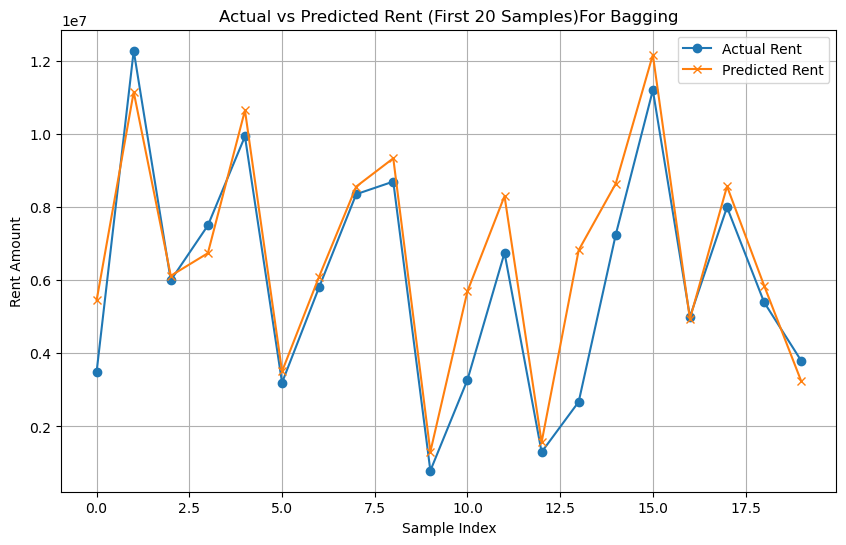

 60%|██████    | 9/15 [00:07<00:06,  1.06s/it]

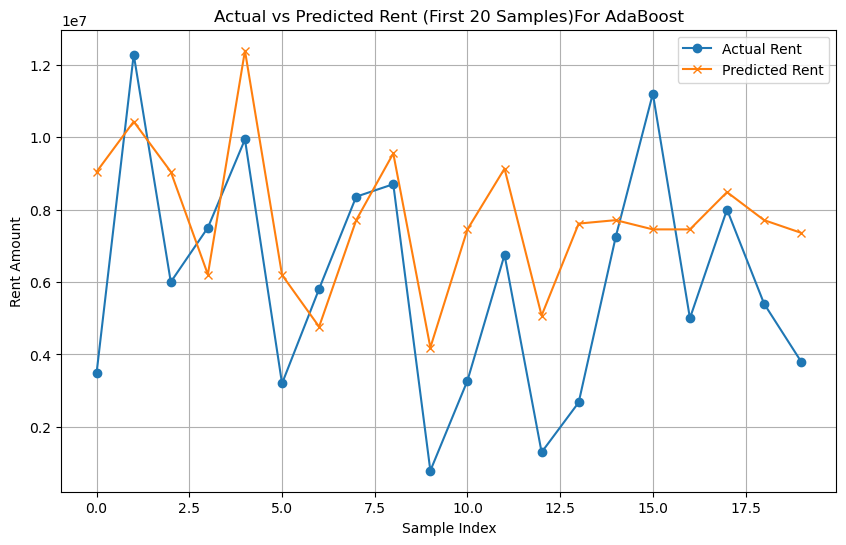

 67%|██████▋   | 10/15 [00:08<00:04,  1.10it/s]

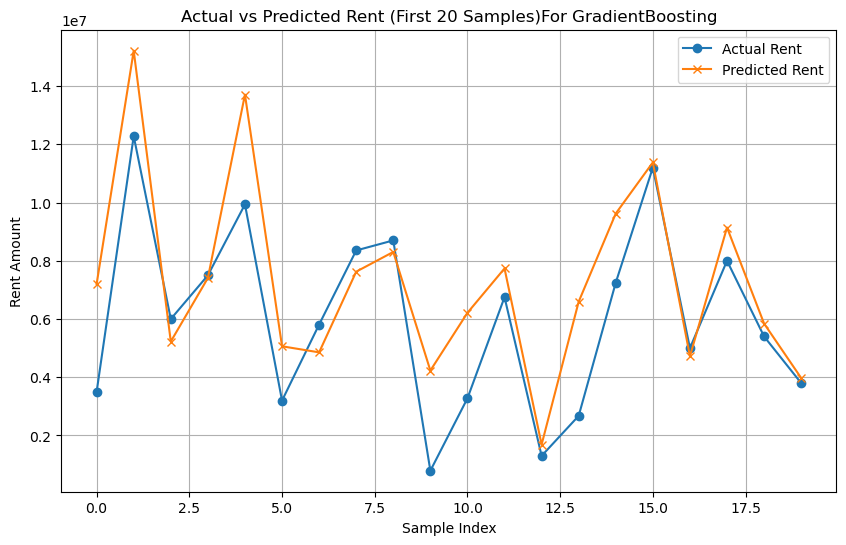

 73%|███████▎  | 11/15 [00:09<00:03,  1.07it/s]

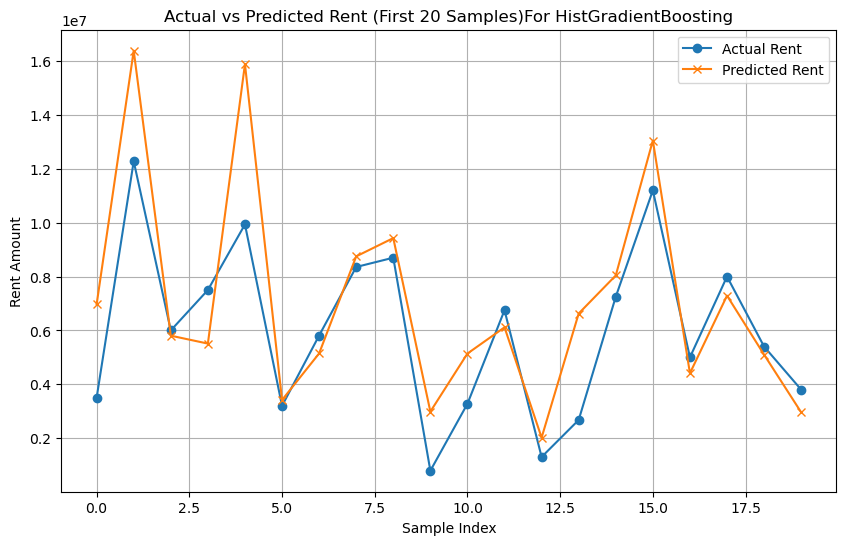

 80%|████████  | 12/15 [01:02<00:50, 16.80s/it]

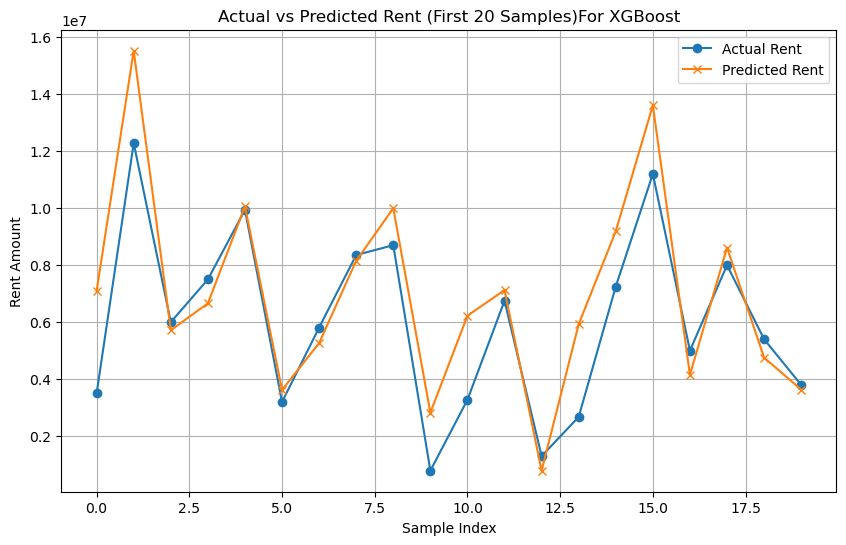

 87%|████████▋ | 13/15 [01:09<00:27, 13.83s/it]

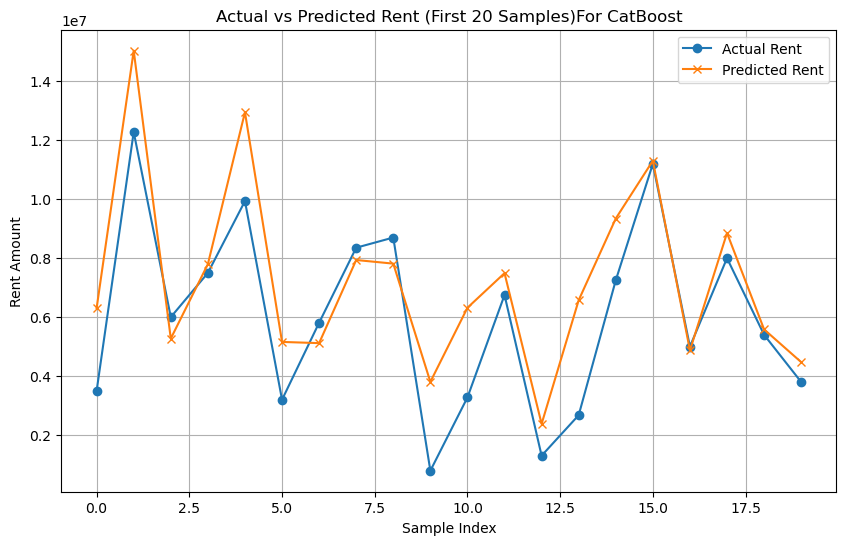

 93%|█████████▎| 14/15 [01:10<00:09,  9.90s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000434 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 316
[LightGBM] [Info] Number of data points in the train set: 3247, number of used features: 22
[LightGBM] [Info] Start training from score 6298607.908839


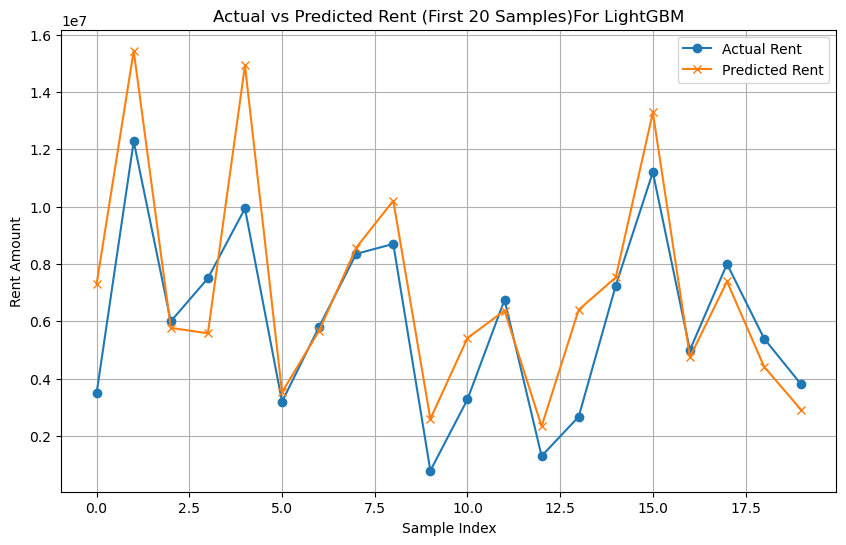

100%|██████████| 15/15 [01:28<00:00,  5.87s/it]


In [164]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train_scaled,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train_scaled, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test_scaled, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test_scaled[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [165]:
res = pd.DataFrame(errors)

In [166]:
res

,Linear Regression,Lasso,Ridge,KNN,SVM,Decision Tree,Random Forest,ExtraTrees,Bagging,AdaBoost,GradientBoosting,HistGradientBoosting,XGBoost,CatBoost,LightGBM
MAE Train,2.320077e+06,2.320072e+06,2.318123e+06,1.712903e+06,2.800813e+06,1.432453e+06,1.498360e+06,4.249366e+04,1.496656e+06,2.776288e+06,1.950322e+06,1.541349e+06,1.428484e+06,1.943502e+06,1.545342e+06
MAE Test,2.158445e+06,2.158441e+06,2.156465e+06,1.963934e+06,2.639722e+06,2.194713e+06,2.011316e+06,1.983497e+06,2.051968e+06,2.864248e+06,1.951707e+06,1.952090e+06,1.993278e+06,1.928700e+06,1.957398e+06
MSE Train,1.705790e+13,1.705790e+13,1.706245e+13,1.181638e+13,2.437978e+13,5.223037e+12,5.528378e+12,7.305755e+10,5.426862e+12,1.408235e+13,1.208901e+13,8.035921e+12,5.364229e+12,1.149825e+13,8.005411e+12
MSE Test,8.524811e+12,8.524802e+12,8.516522e+12,8.731348e+12,1.383614e+13,2.172933e+13,1.349017e+13,1.978488e+13,1.330623e+13,2.125953e+13,7.434664e+12,8.998664e+12,1.204348e+13,7.340897e+12,9.115597e+12
RMSE Train,4.130121e+06,4.130121e+06,4.130671e+06,3.437496e+06,4.937588e+06,2.285396e+06,2.351250e+06,2.702916e+05,2.329563e+06,3.752646e+06,3.476925e+06,2.834770e+06,2.316081e+06,3.390907e+06,2.829384e+06
RMSE Test,2.919728e+06,2.919726e+06,2.918308e+06,2.954885e+06,3.719696e+06,4.661473e+06,3.672897e+06,4.448020e+06,3.647770e+06,4.610806e+06,2.726658e+06,2.999777e+06,3.470372e+06,2.709409e+06,3.019205e+06
R2 Train,2.846950e-01,2.846950e-01,2.845041e-01,5.044926e-01,-2.234051e-02,7.809774e-01,7.681733e-01,9.969364e-01,7.724302e-01,4.094714e-01,4.930602e-01,6.630221e-01,7.750567e-01,5.178328e-01,6.643015e-01
R2 Test,3.724959e-01,3.724966e-01,3.731061e-01,3.572929e-01,-1.846631e-02,-5.994773e-01,7.000024e-03,-4.563480e-01,2.053991e-02,-5.648962e-01,4.527407e-01,3.376160e-01,1.134893e-01,4.596428e-01,3.290087e-01


In [167]:
res

,Linear Regression,Lasso,Ridge,KNN,SVM,Decision Tree,Random Forest,ExtraTrees,Bagging,AdaBoost,GradientBoosting,HistGradientBoosting,XGBoost,CatBoost,LightGBM
MAE Train,2.320077e+06,2.320072e+06,2.318123e+06,1.712903e+06,2.800813e+06,1.432453e+06,1.498360e+06,4.249366e+04,1.496656e+06,2.776288e+06,1.950322e+06,1.541349e+06,1.428484e+06,1.943502e+06,1.545342e+06
MAE Test,2.158445e+06,2.158441e+06,2.156465e+06,1.963934e+06,2.639722e+06,2.194713e+06,2.011316e+06,1.983497e+06,2.051968e+06,2.864248e+06,1.951707e+06,1.952090e+06,1.993278e+06,1.928700e+06,1.957398e+06
MSE Train,1.705790e+13,1.705790e+13,1.706245e+13,1.181638e+13,2.437978e+13,5.223037e+12,5.528378e+12,7.305755e+10,5.426862e+12,1.408235e+13,1.208901e+13,8.035921e+12,5.364229e+12,1.149825e+13,8.005411e+12
MSE Test,8.524811e+12,8.524802e+12,8.516522e+12,8.731348e+12,1.383614e+13,2.172933e+13,1.349017e+13,1.978488e+13,1.330623e+13,2.125953e+13,7.434664e+12,8.998664e+12,1.204348e+13,7.340897e+12,9.115597e+12
RMSE Train,4.130121e+06,4.130121e+06,4.130671e+06,3.437496e+06,4.937588e+06,2.285396e+06,2.351250e+06,2.702916e+05,2.329563e+06,3.752646e+06,3.476925e+06,2.834770e+06,2.316081e+06,3.390907e+06,2.829384e+06
RMSE Test,2.919728e+06,2.919726e+06,2.918308e+06,2.954885e+06,3.719696e+06,4.661473e+06,3.672897e+06,4.448020e+06,3.647770e+06,4.610806e+06,2.726658e+06,2.999777e+06,3.470372e+06,2.709409e+06,3.019205e+06
R2 Train,2.846950e-01,2.846950e-01,2.845041e-01,5.044926e-01,-2.234051e-02,7.809774e-01,7.681733e-01,9.969364e-01,7.724302e-01,4.094714e-01,4.930602e-01,6.630221e-01,7.750567e-01,5.178328e-01,6.643015e-01
R2 Test,3.724959e-01,3.724966e-01,3.731061e-01,3.572929e-01,-1.846631e-02,-5.994773e-01,7.000024e-03,-4.563480e-01,2.053991e-02,-5.648962e-01,4.527407e-01,3.376160e-01,1.134893e-01,4.596428e-01,3.290087e-01
